# Lecture 2: Global Explanations — Feature Effects

**Kristian Boroz · opencampus.sh**  
**Running example:** California housing, predicting median house value (target in $100k) with a gradient-boosting regressor; small synthetic examples expose known interaction and correlation behavior.

## Motivation

For every feature, ask two different questions:

- **How much does it matter?** Measure predictive reliance with **Permutation Feature Importance (PFI)**.
- **How does it matter?** Inspect prediction effects with **PDP**, **ICE**, and **ALE**.

These are **global, model-agnostic, post-hoc** methods: they inspect a fitted model after training and need only calls to `model.predict` (and, for PFI, a score). They summarize model behavior over a dataset, not a single prediction; local explanations are the focus of Lectures 3–4. All describe the model, not causal effects in the world.


In [1]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

data = fetch_california_housing(as_frame=True)
X = data.data.sample(6000, random_state=0)
y = data.target.loc[X.index]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
model = HistGradientBoostingRegressor(random_state=0).fit(X_train, y_train)
print("R^2 train/test:", model.score(X_train, y_train), model.score(X_test, y_test))

def add_x_rug(ax, values, color="#526579", alpha=.28):
    """Add observed x-values as rug ticks just below the plotting area."""
    values = np.asarray(values)
    ax.plot(values, np.zeros_like(values), "|", transform=ax.get_xaxis_transform(),
            color=color, alpha=alpha, markersize=6, clip_on=False)
X.describe().T[["mean","std","min","max"]]

R^2 train/test: 0.9212787733108296 0.8175200600999386


,mean,std,min,max
MedInc,3.871068,1.918971,0.499900,15.000100
HouseAge,28.699667,12.535496,1.000000,52.000000
AveRooms,5.435057,2.893206,1.465753,141.909091
AveBedrms,1.101466,0.526502,0.500000,25.636364
Population,1429.983167,1095.051692,8.000000,16305.000000
AveOccup,3.147724,16.046533,0.692308,1243.333333
Latitude,35.633793,2.126724,32.560000,41.950000
Longitude,-119.574738,1.996798,-124.300000,-114.490000


## PFI — Permutation Feature Importance

**Idea:** destroy the information carried by one feature and measure how much predictive performance suffers. On held-out test data, let the baseline score be $s=S(f,X,y)$. For feature $j$, shuffle only its column to obtain $s_{\mathrm{perm},j}$. With a score where larger is better,

$$\mathrm{PFI}_j=s-s_{\mathrm{perm},j},$$

or, for an error measure where smaller is better, report the error ratio $e_{\mathrm{perm},j}/e_{\mathrm{orig}}$. Repeat the shuffle several times; report the mean and spread (e.g. standard deviation), since the permutation is random. PFI is a magnitude of reliance, **not a direction** of effect.

Use held-out data: a model that overfits can show large importance for noise features in training data (Breiman, 2001; Molnar, 2022). Correlated features complicate the interpretation: shuffling one breaks feature relationships and can create unrealistic rows (for example, rooms far exceeding bedrooms); importance can also be split between substitutes. A useful remedy is to permute a correlated group together, while remembering this is still a model-reliance test.


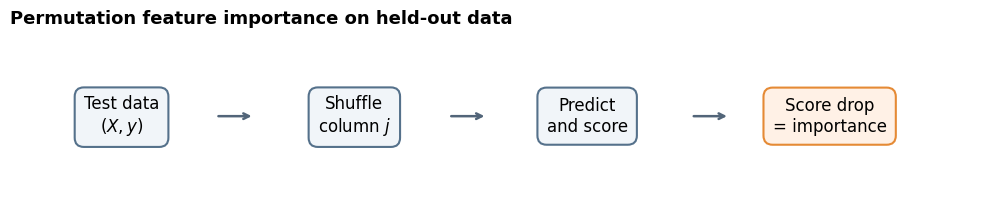

In [2]:
# PFI in one pass: the same test examples are rescored after one column is shuffled.
fig, ax = plt.subplots(figsize=(10, 2.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis('off')
boxes=[(0.25, 'Test data\n$(X,y)$'), (2.65, 'Shuffle\ncolumn $j$'), (5.05, 'Predict\nand score'), (7.55, 'Score drop\n= importance')]
for x, label in boxes:
    ax.text(x+0.9, 1, label, ha='center', va='center', fontsize=12,
            bbox=dict(boxstyle='round,pad=.55', fc='#F1F5F9' if x<7 else '#FFF1E6', ec='#55718B' if x<7 else '#E58A35', lw=1.5))
for x in [2.12, 4.52, 7.02]:
    ax.annotate('', xy=(x+0.4,1), xytext=(x,1), arrowprops=dict(arrowstyle='->', lw=1.8, color='#526579'))
ax.set_title('Permutation feature importance on held-out data', loc='left', fontsize=13, weight='bold')
plt.tight_layout(); plt.show()


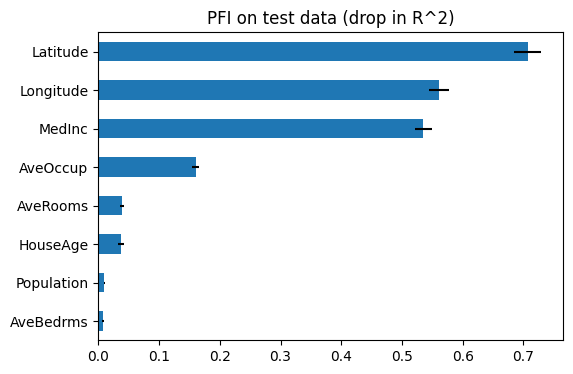

In [3]:
pfi = permutation_importance(model, X_test, y_test, n_repeats=15, random_state=0)
imp = pd.DataFrame({"mean": pfi.importances_mean, "std": pfi.importances_std}, index=X.columns).sort_values("mean")
imp["mean"].plot.barh(xerr=imp["std"], figsize=(6,4), title="PFI on test data (drop in R^2)")
plt.show()

**TODO 1.** Compute PFI on the *training* set and compare with the test-set PFI. Do the rankings differ? When would a large gap signal overfitting?

**TODO 2.** `AveRooms` and `AveBedrms` are correlated. Check the correlation, then permute them *together* as a group (shuffle the two columns with the same row permutation) and compare the group drop with the two individual drops. What does this show about PFI and correlated features?

**Interpretation guide.** Strong training importance that substantially shrinks on held-out data can indicate that a model learned training-specific patterns (especially when paired with a train/test performance gap). With correlated predictors, permuting one column leaves its proxy available to the model, often understating either feature's individual importance. Joint permutation removes the shared information, but can still create off-manifold combinations with other predictors; it is a model-reliance test, not a causal attribution.


Training ranking (largest first): ['Latitude', 'MedInc', 'Longitude', 'AveOccup', 'AveRooms', 'HouseAge', 'Population', 'AveBedrms']
Test ranking (largest first): ['Latitude', 'Longitude', 'MedInc', 'AveOccup', 'AveRooms', 'HouseAge', 'Population', 'AveBedrms']
Train/test R^2: 0.921 0.818
Mean train-minus-test importance: 0.0397


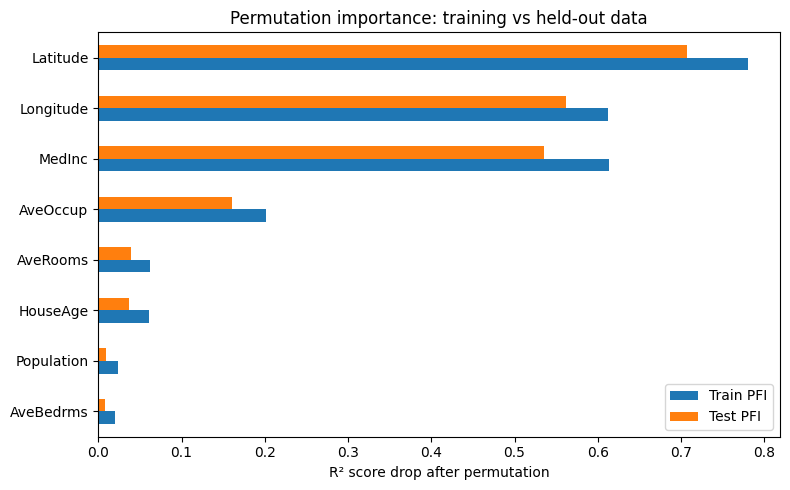

AveRooms/AveBedrms correlation:
            AveRooms  AveBedrms
AveRooms    1.00000    0.88834
AveBedrms   0.88834    1.00000
Held-out R² baseline: 0.8175; joint AveRooms+AveBedrms drop: 0.0435
Individual held-out PFI means: {'AveRooms': 0.0386, 'AveBedrms': 0.0079}


In [4]:
# TODO 1: compare train and held-out permutation importance using the same settings.
pfi_train = permutation_importance(model, X_train, y_train, n_repeats=15, random_state=0, scoring="r2")
pfi_test = permutation_importance(model, X_test, y_test, n_repeats=15, random_state=0, scoring="r2")
train_imp = pd.Series(pfi_train.importances_mean, index=X.columns)
test_imp = pd.Series(pfi_test.importances_mean, index=X.columns)
print("Training ranking (largest first):", train_imp.sort_values(ascending=False).index.tolist())
print("Test ranking (largest first):", test_imp.sort_values(ascending=False).index.tolist())
print("Train/test R^2:", round(model.score(X_train, y_train), 3), round(model.score(X_test, y_test), 3))
print("Mean train-minus-test importance:", round((train_imp - test_imp).mean(), 4))
compare = pd.DataFrame({"Train PFI": train_imp, "Test PFI": test_imp}).sort_values("Test PFI")
ax = compare.plot.barh(figsize=(8, 5), title="Permutation importance: training vs held-out data")
ax.set_xlabel("R² score drop after permutation")
plt.tight_layout(); plt.show()

# TODO 2: paired shuffle keeps the two selected columns aligned with one another.
print("AveRooms/AveBedrms correlation:\n", X[["AveRooms", "AveBedrms"]].corr())
rng_group = np.random.RandomState(0)
Xp = X_test.copy()
perm = rng_group.permutation(len(Xp))
Xp.loc[:, ["AveRooms", "AveBedrms"]] = X_test[["AveRooms", "AveBedrms"]].iloc[perm].to_numpy()
baseline_r2 = model.score(X_test, y_test)
group_drop = baseline_r2 - model.score(Xp, y_test)
print(f"Held-out R² baseline: {baseline_r2:.4f}; joint AveRooms+AveBedrms drop: {group_drop:.4f}")
print("Individual held-out PFI means:", {k: round(float(test_imp[k]), 4) for k in ["AveRooms", "AveBedrms"]})


## PDP and ICE

### Partial dependence (PDP)

For feature set $S$ and its complement $C$, the partial dependence (Friedman, 2001) is

$$f_S(x_S)=\mathbb{E}_{X_C}[f(x_S,X_C)]pproxrac{1}{n}\sum_{i=1}^n f(x_S,x_C^{(i)}).$$

Read this as the **average prediction if everyone had value $x_S$**. Build a grid of feature values, replace the feature(s) for every row, and make $n$ predictions at each grid point. Two-dimensional PDPs show a joint effect. PDP relies on independence of $X_S$ and $X_C$ for plausible feature combinations; with correlated inputs it may evaluate unrealistic rows. An average can hide heterogeneous responses; show data density (rug or histogram) because sparse-range curves may extrapolate. A PDP is descriptive, not causal.

**How a PDP is built.** Each blue curve is an instance-level prediction over the feature grid; orange dots mark selected grid values. At each grid value, average the instance predictions (orange PDP on the right). The bottom rug is dense at low values and sparse at high values, where the curve has less support.

### Individual conditional expectation (ICE)

ICE (Goldstein et al., 2015) plots $f(x_S,x_C^{(i)})$ for each instance $i$, holding its other features fixed as $x_S$ varies. The PDP is the average of the ICE curves. ICE reveals heterogeneous slopes and interactions that a global average can conceal.

Scikit-learn examples used below:
```python
PartialDependenceDisplay.from_estimator(model, X_train, ['MedInc'], kind='both', subsample=60)
PartialDependenceDisplay.from_estimator(model, X_train, [('Latitude', 'Longitude')], kind='average')
```


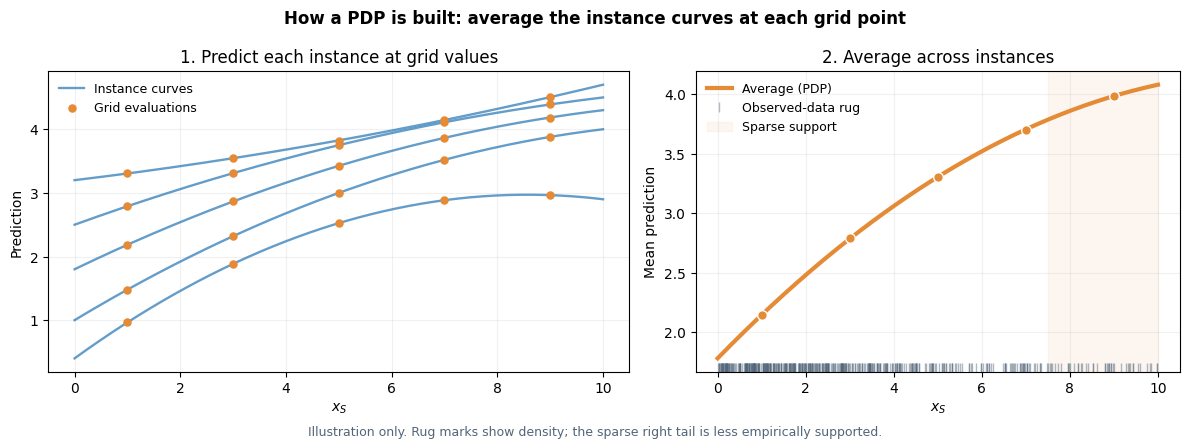

In [5]:
# Schematic reconstruction: per-instance curves (left), their pointwise average (right).
x_demo = np.linspace(0, 10, 300)
curves_demo = np.vstack([
    1.0 + 0.5*x_demo - 0.02*x_demo**2,
    2.5 + 0.3*x_demo - 0.01*x_demo**2,
    0.4 + 0.6*x_demo - 0.035*x_demo**2,
    3.2 + 0.1*x_demo + 0.005*x_demo**2,
    1.8 + 0.4*x_demo - 0.015*x_demo**2,
])
grid_marks = np.array([1, 3, 5, 7, 9])
mark_idx = [np.argmin(np.abs(x_demo-g)) for g in grid_marks]
pdp_demo = curves_demo.mean(axis=0)
rng_demo = np.random.RandomState(21)
# Many observations at the left and progressively fewer on the right.
rug_demo = np.r_[rng_demo.beta(1.2, 3.4, 430)*10, rng_demo.uniform(5.7, 10, 70)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={'width_ratios':[1.2,1]})
for k, curve in enumerate(curves_demo):
    ax1.plot(x_demo, curve, color='#2878B5', alpha=.72, lw=1.7,
             label='Instance curves' if k==0 else None)
    ax1.scatter(grid_marks, curve[mark_idx], color='#E58A35', s=26, zorder=3,
                label='Grid evaluations' if k==0 else None)
ax1.set(title='1. Predict each instance at grid values', xlabel='$x_S$', ylabel='Prediction')
ax1.legend(frameon=False, fontsize=9); ax1.grid(alpha=.18)
ax2.plot(x_demo, pdp_demo, color='#E58A35', lw=3, label='Average (PDP)')
ax2.scatter(grid_marks, pdp_demo[mark_idx], color='#E58A35', edgecolor='white', s=48, zorder=3)
ax2.plot(rug_demo, np.full_like(rug_demo, .015), '|', transform=ax2.get_xaxis_transform(),
         color='#516579', alpha=.45, markersize=7, label='Observed-data rug')
ax2.axvspan(7.5, 10, color='#E58A35', alpha=.07, label='Sparse support')
ax2.set(title='2. Average across instances', xlabel='$x_S$', ylabel='Mean prediction')
ax2.legend(frameon=False, fontsize=9); ax2.grid(alpha=.18)
fig.suptitle('How a PDP is built: average the instance curves at each grid point', weight='bold')
fig.text(.5, -.01, 'Illustration only. Rug marks show density; the sparse right tail is less empirically supported.', ha='center', fontsize=9, color='#526579')
plt.tight_layout(); plt.show()


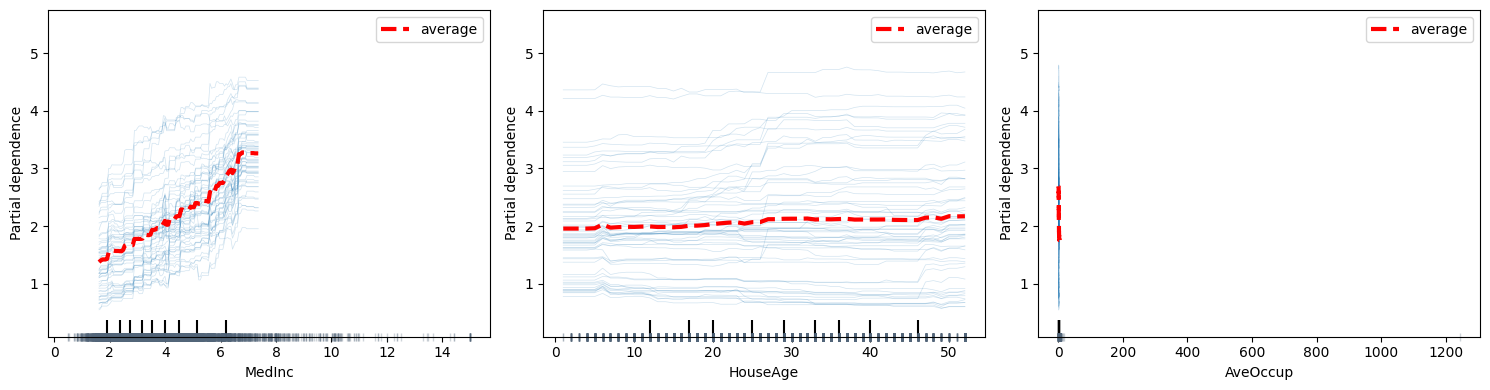

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
PartialDependenceDisplay.from_estimator(model, X_train, ["MedInc","HouseAge","AveOccup"], kind="both",
    subsample=60, random_state=0, ax=ax, ice_lines_kw={"alpha":0.2}, pd_line_kw={"color":"red","lw":3})
for a, feat in zip(ax, ["MedInc", "HouseAge", "AveOccup"]):
    add_x_rug(a, X_train[feat])
plt.tight_layout(); plt.show()

**TODO 3.** Interpret the `MedInc` and `HouseAge` curves in plain language. Is the effect monotonic? Where does the ICE spread suggest interactions?

**TODO 4.** Draw a 2D PDP for `Latitude` and `Longitude` (pass `[ ("Latitude","Longitude") ]` and `kind="average"`). What does it show that the 1D plots cannot? Which map of California does it resemble?

**Worked interpretation.** In this fitted housing model, inspect the red average lines: `MedInc` is expected to have a clear generally increasing but nonlinear relationship with predicted value, often flattening near the high-income end; `HouseAge` is weaker and can flatten or bend rather than remain a constant linear rise. ICE lines that fan out or cross—particularly at larger values—show that the average effect is not shared uniformly and suggest interactions with the other predictors. The 2D geographic surface preserves the joint location pattern, including localized high/low value regions, that separate latitude and longitude averages erase; it typically resembles the California coast/urban-corridor housing-value pattern. These are qualitative readings of the plotted fitted model.


MedInc: PDP range=1.902; increasing steps=41, decreasing steps=27


HouseAge: PDP range=0.215; increasing steps=30, decreasing steps=13


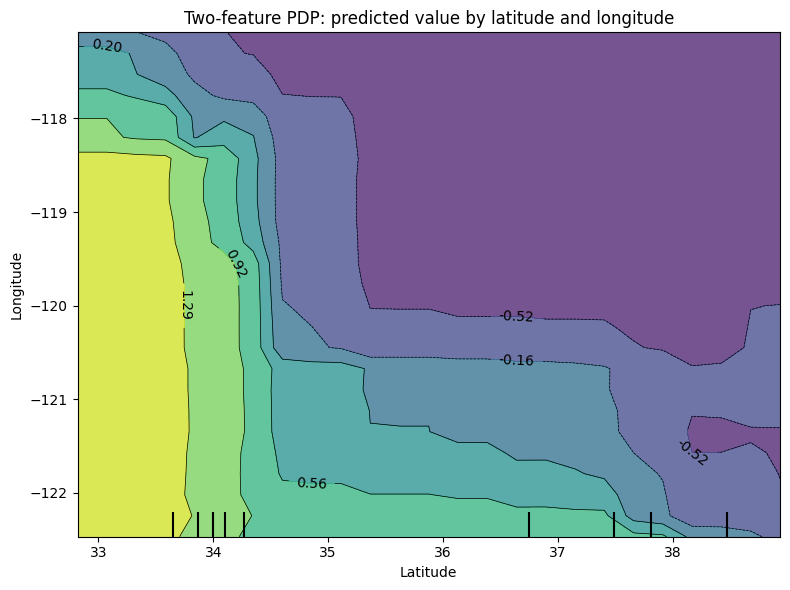

In [7]:
# TODO 3: quantify whether average effects are monotone and show ICE heterogeneity.
for feat in ["MedInc", "HouseAge"]:
    display = PartialDependenceDisplay.from_estimator(model, X_train, [feat], kind="both", subsample=100, random_state=0)
    pd_values = np.asarray(display.pd_results[0]["average"]).ravel()
    diffs = np.diff(pd_values)
    for a in display.axes_.ravel(): add_x_rug(a, X_train[feat])
    print(f"{feat}: PDP range={pd_values.max()-pd_values.min():.3f}; increasing steps={(diffs>1e-3).sum()}, decreasing steps={(diffs < -1e-3).sum()}")
    plt.close(display.figure_)

# TODO 4: two-dimensional average partial dependence for geographic coordinates.
fig, ax = plt.subplots(figsize=(8, 6))
PartialDependenceDisplay.from_estimator(model, X_train, [("Latitude", "Longitude")], kind="average", grid_resolution=25, ax=ax)
ax.set_title("Two-feature PDP: predicted value by latitude and longitude")
plt.tight_layout(); plt.show()


## ALE — Accumulated Local Effects

**Problem with PDP:** changing a feature across its full range can combine values that never co-occur in correlated data. **ALE** (Apley & Zhu, 2020) uses only instances inside a small interval of $x_j$, computes local prediction differences at the interval's edges while keeping all other features at their observed values, then accumulates those differences.

With quantile-bin edges $z_0,\ldots,z_K$ and bin observations $N_k=\{i:x_j^{(i)}\in(z_{k-1},z_k]\}$, a centered first-order ALE curve is

$$\operatorname{ALE}_j(x)=\sum_{k=1}^{k_j(x)}rac{1}{n_k}\sum_{i\in N_k}\left[f(z_k,x_{\setminus j}^{(i)})-f(z_{k-1},x_{\setminus j}^{(i)})ight]-c,$$

where $n_k=|N_k|$, $k_j(x)$ is the bin containing $x$, and $c$ centers the accumulated curve. Other features stay at their observed values. This notebook implements 1D ALE by hand; libraries include **PyALE** and **Alibi**.

| Question | PDP | ALE |
|---|---|---|
| Correlated features | May evaluate unrealistic combinations | Local differences on observed support; generally more robust |
| Interactions | Averaged over other features; can hide heterogeneity | Average local main effect; interaction structure still needs inspection |
| Interpretation | Absolute mean prediction (often centered for display) | Relative effect around the centered mean |
| Cost (1D) | About $n	imes$ grid predictions | About $2n$ predictions across bins |
| Ease of explanation | Very intuitive “average if everyone had $x$” | Requires explaining local differences and accumulation |

ALE is not a cure for sparse data or all interactions; bin choices matter.


<>:12: SyntaxWarning: invalid escape sequence '\D'
<>:12: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_242/3140595466.py:12: SyntaxWarning: invalid escape sequence '\D'
  ax1.annotate(f'local $\Delta_k={local[k]:+.2f}$', xy=(mid,.31), ha='center', color='#2878B5', fontsize=9)


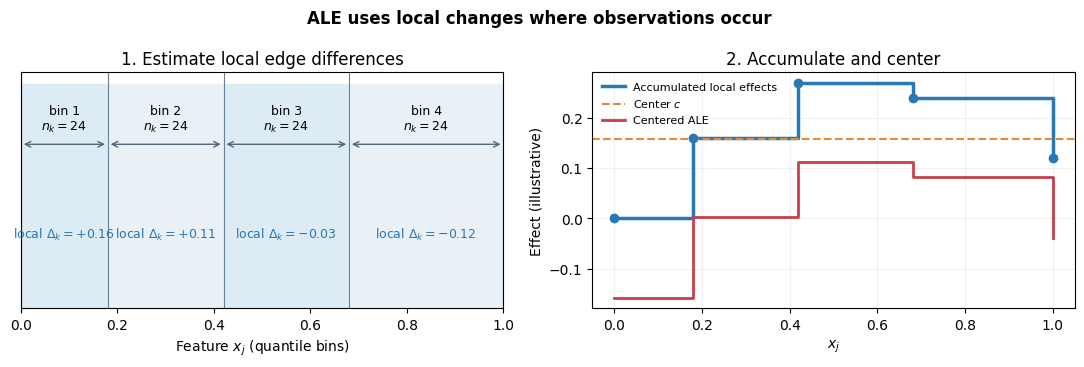

In [8]:
# Quantile-bin ALE illustration: local endpoint differences are accumulated, then centered.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.7))
edge = np.array([0.0, .18, .42, .68, 1.0])
counts = [24, 24, 24, 24]  # equal-frequency quantile bins (schematic)
local = np.array([.16, .11, -.03, -.12])
accum = np.r_[0, np.cumsum(local)]
for k in range(4):
    mid=(edge[k]+edge[k+1])/2
    ax1.fill_between([edge[k],edge[k+1]], [0,0], [1,1], color=['#DCEAF5','#E8F1F7'][k%2], alpha=.95)
    ax1.annotate('', xy=(edge[k+1],.73), xytext=(edge[k],.73), arrowprops=dict(arrowstyle='<->', color='#526579'))
    ax1.text(mid,.84,f'bin {k+1}\n$n_k={counts[k]}$',ha='center',va='center',fontsize=9)
    ax1.annotate(f'local $\Delta_k={local[k]:+.2f}$', xy=(mid,.31), ha='center', color='#2878B5', fontsize=9)
for e in edge: ax1.axvline(e, color='#668096', lw=.8)
ax1.set(xlim=(0,1),ylim=(0,1.05),xlabel='Feature $x_j$ (quantile bins)',yticks=[],title='1. Estimate local edge differences')
ax1.set_yticklabels([])
ax2.step(edge, accum, where='post', color='#2878B5', lw=2.5, label='Accumulated local effects')
ax2.scatter(edge, accum, color='#2878B5', zorder=3)
center=accum.mean(); ax2.axhline(center, color='#E58A35', ls='--', label='Center $c$')
ax2.step(edge, accum-center, where='post', color='#C83E4D', lw=2, label='Centered ALE')
ax2.set(xlabel='$x_j$',ylabel='Effect (illustrative)',title='2. Accumulate and center'); ax2.grid(alpha=.18); ax2.legend(frameon=False,fontsize=8)
fig.suptitle('ALE uses local changes where observations occur',weight='bold')
plt.tight_layout(); plt.show()


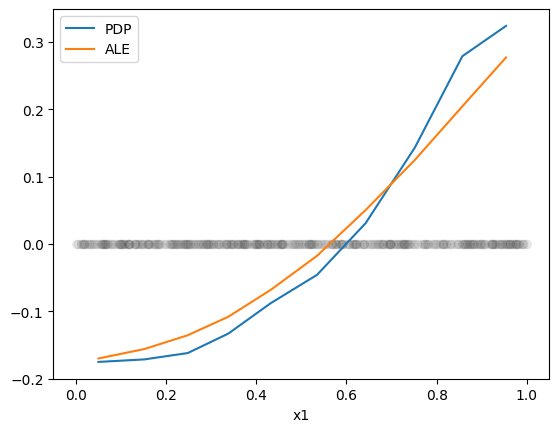

In [9]:
def ale_1d(model, X, feat, bins=10):
    x = X[feat].values
    edges = np.unique(np.quantile(x, np.linspace(0, 1, bins + 1)))
    idx = np.clip(np.digitize(x, edges[1:-1], right=True), 0, len(edges) - 2)
    eff, cnt = np.zeros(len(edges) - 1), np.zeros(len(edges) - 1)
    for k in range(len(edges) - 1):
        m = idx == k
        if m.sum() == 0: continue
        lo, hi = X[m].copy(), X[m].copy()
        lo[feat], hi[feat] = edges[k], edges[k + 1]
        eff[k] = (model.predict(hi) - model.predict(lo)).mean(); cnt[k] = m.sum()
    ale = np.r_[0, np.cumsum(eff)]
    ale_mid = (ale[:-1] + ale[1:]) / 2
    ale_mid -= np.sum(ale_mid * cnt) / cnt.sum()          # centre
    return (edges[:-1] + edges[1:]) / 2, ale_mid

def pdp_1d(model, X, feat, grid):
    out = []
    for g in grid:
        t = X.copy(); t[feat] = g; out.append(model.predict(t).mean())
    return np.array(out) - np.mean(out)

rng = np.random.RandomState(0); n = 1000
# x2 is almost a copy of x1; true function y = x1 * x2  (so y ~ x1^2 on the data)
x1 = rng.uniform(0, 1, n); x2 = x1 + rng.normal(0, 0.05, n)
Xc = pd.DataFrame({"x1": x1, "x2": x2}); yc = x1 * x2 + rng.normal(0, 0.02, n)
rf_c = RandomForestRegressor(200, min_samples_leaf=5, random_state=0).fit(Xc, yc)

centers, ale = ale_1d(rf_c, Xc, "x1")
pdp = pdp_1d(rf_c, Xc, "x1", centers)
plt.plot(centers, pdp, label="PDP"); plt.plot(centers, ale, label="ALE")
plt.scatter(Xc["x1"], Xc["x2"] * 0, alpha=0.02, color="k")   # rug
plt.xlabel("x1"); plt.legend(); plt.show()

**TODO 6.** Add the "on-the-data" reference curve $E[y \mid x_1]$ (use `centers**2`, centred the same way) and compare PDP and ALE. Which is closer, and why? Hint: the PDP evaluates the model at $(x_1, x_2)$ combinations such as $(0.1, 0.9)$ that never occur in the data.

**TODO 7.** Apply `ale_1d` to the California model for `MedInc` and `AveRooms` and compare with the PDPs. Where do they disagree?

For a one-feature model view, a centered reference curve can be drawn as $m(x_1)=x_1^2-\operatorname{mean}(x_1^2)$, matching the centered vertical scales of the ALE/PDP estimates. On real California data, compare the shapes over the observed support; PDP/ALE differences are most informative where the companion features are strongly dependent or the predictor grid reaches sparse regions.


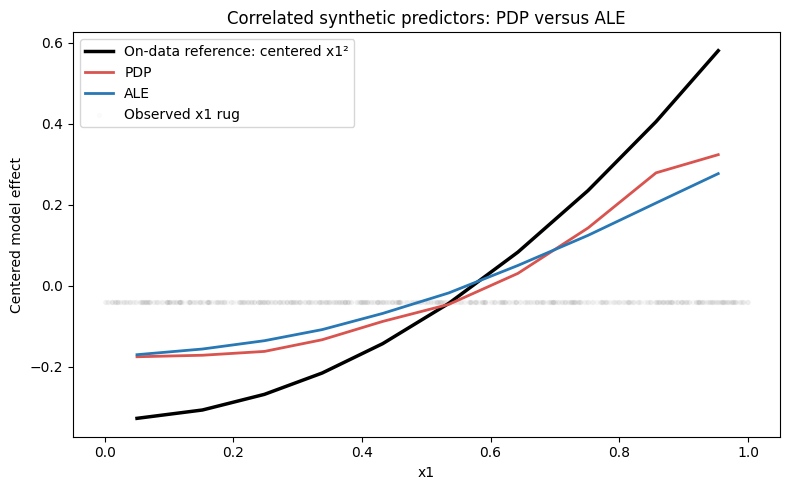

Correlation x1/x2: 0.986
Visual check: ALE typically tracks the centered in-support quadratic pattern more closely; PDP averages over mismatched x2 values.


MedInc: maximum absolute centered PDP-ALE gap = 0.445


AveRooms: maximum absolute centered PDP-ALE gap = 0.136


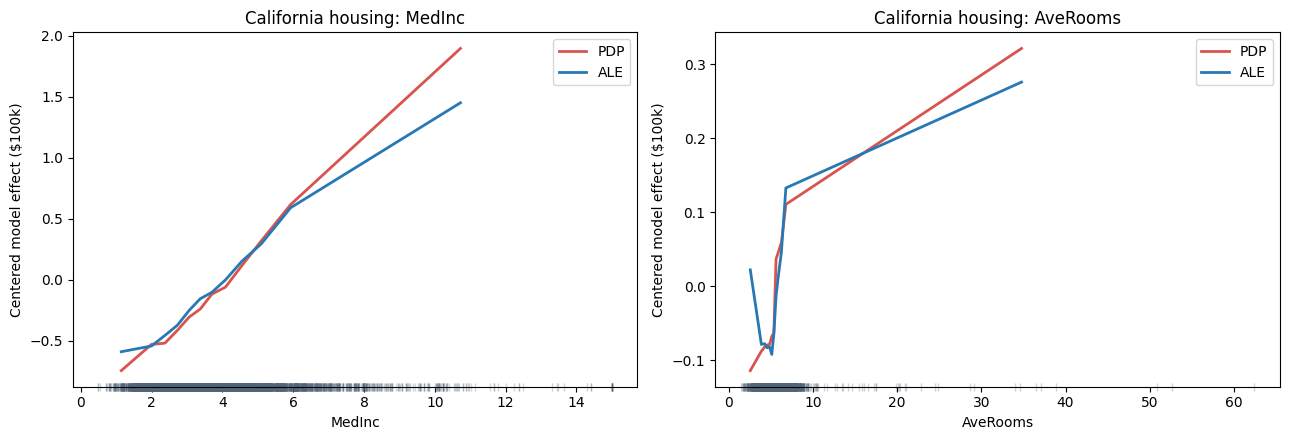

In [10]:
# TODO 6: add a centered on-the-data reference curve for y ≈ x1².
centers, ale = ale_1d(rf_c, Xc, "x1")
pdp = pdp_1d(rf_c, Xc, "x1", centers)
reference = centers ** 2
reference = reference - reference.mean()
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(centers, reference, label="On-data reference: centered x1²", lw=2.5, color="black")
ax.plot(centers, pdp, label="PDP", lw=2, color="#D9534F")
ax.plot(centers, ale, label="ALE", lw=2, color="#2878B5")
ax.scatter(Xc["x1"], Xc["x2"] * 0 - 0.04, alpha=0.025, color="gray", s=8, label="Observed x1 rug")
ax.set(xlabel="x1", ylabel="Centered model effect", title="Correlated synthetic predictors: PDP versus ALE")
ax.legend(); plt.tight_layout(); plt.show()
print("Correlation x1/x2:", round(float(Xc.corr().iloc[0, 1]), 3))
print("Visual check: ALE typically tracks the centered in-support quadratic pattern more closely; PDP averages over mismatched x2 values.")

# TODO 7: compare ALE to centered PDP over the observed California feature support.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feat in zip(axes, ["MedInc", "AveRooms"]):
    centers_ca, ale_ca = ale_1d(model, X_train, feat, bins=12)
    pdp_ca = pdp_1d(model, X_train, feat, centers_ca)
    ax.plot(centers_ca, pdp_ca, label="PDP", lw=2, color="#D9534F")
    ax.plot(centers_ca, ale_ca, label="ALE", lw=2, color="#2878B5")
    ax.set(xlabel=feat, ylabel="Centered model effect ($100k)", title=f"California housing: {feat}")
    add_x_rug(ax, X_train[feat])
    ax.legend()
    print(f"{feat}: maximum absolute centered PDP-ALE gap = {np.max(np.abs(pdp_ca-ale_ca)):.3f}")
plt.tight_layout(); plt.show()


## Interactions and limitations

An interaction means the effect of $x_j$ depends on another feature. Detect it with ICE spread (curves fan out or cross), 2D PDPs, or **Friedman's $H$-statistic**, which summarizes the share of variation attributable to interaction beyond additive main effects. For California housing, latitude and longitude jointly encode location: only the 2D surface reveals coastal/urban price structure; 1D effects show only marginal main effects.

The $y=u\,z$, $z\in\{-1,+1\}$ demonstration below has a flat PDP because opposite conditional slopes cancel, even though $u$ matters within either group (the same issue can arise in a random-forest model). Global curves can hide local behavior, and plots are sensitive to model, sample, grid, and support. These are descriptions of a model, not causal claims.


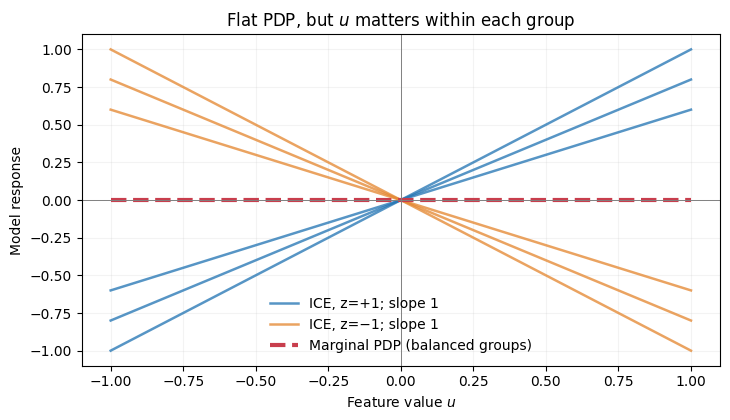

In [11]:
# Interaction schematic: y = u*z. Several conditional slopes, one flat marginal average.
u_demo = np.linspace(-1, 1, 200)
fig, ax = plt.subplots(figsize=(7.4, 4.3))
for slope in [1.0, .8, .6]:
    ax.plot(u_demo, slope*u_demo, color='#2878B5', lw=1.8, alpha=.78,
            label=f'ICE, z=+1; slope {slope:g}' if slope==1.0 else None)
for slope in [1.0, .8, .6]:
    ax.plot(u_demo, -slope*u_demo, color='#E58A35', lw=1.8, alpha=.78,
            label=f'ICE, z=−1; slope {slope:g}' if slope==1.0 else None)
ax.plot(u_demo, np.zeros_like(u_demo), color='#C83E4D', lw=3, ls='--', label='Marginal PDP (balanced groups)')
ax.axhline(0, color='gray', lw=.7); ax.axvline(0, color='gray', lw=.7)
ax.set(xlabel='Feature value $u$', ylabel='Model response', title='Flat PDP, but $u$ matters within each group')
ax.legend(frameon=False, ncol=1); ax.grid(alpha=.15); plt.tight_layout(); plt.show()


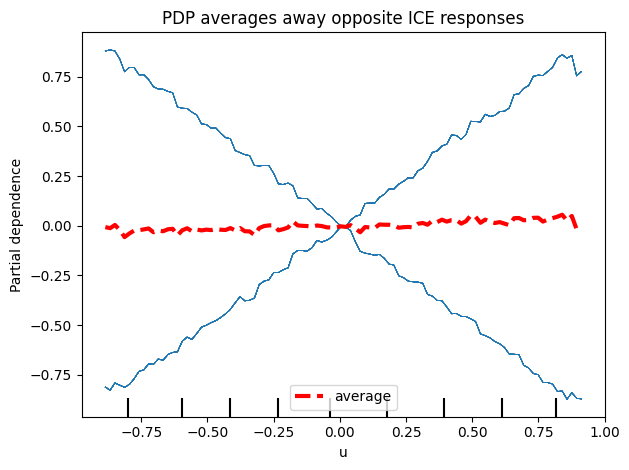

Mean absolute within-group endpoint change, z=+1/-1: {-1: 1.61, 1: 1.627}


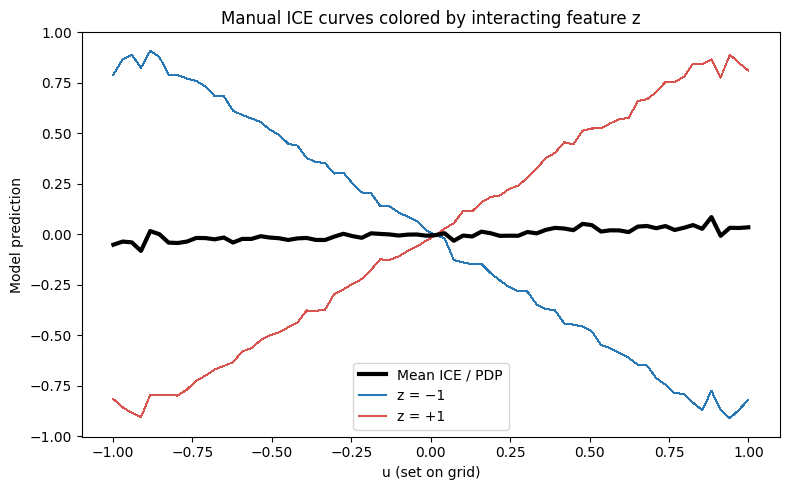

In [12]:
# Synthetic interaction: the PDP averages away opposite conditional trends.
rng = np.random.RandomState(0); n = 1000
u = rng.uniform(-1, 1, n); z = rng.choice([-1, 1], n)
Xi = pd.DataFrame({"u": u, "z": z}); yi = u * z + rng.normal(0, 0.05, n)
rf_i = RandomForestRegressor(200, min_samples_leaf=5, random_state=0).fit(Xi, yi)
PartialDependenceDisplay.from_estimator(rf_i, Xi, ["u"], kind="both", subsample=100, random_state=0,
    ice_lines_kw={"alpha":0.3}, pd_line_kw={"color":"red","lw":3})
plt.title("PDP averages away opposite ICE responses")
plt.tight_layout(); plt.show()

# Manual ICE: keep each row's z fixed while setting u to each grid value.
grid = np.linspace(Xi["u"].min(), Xi["u"].max(), 70)
curves = np.empty((len(Xi), len(grid)))
for j, value in enumerate(grid):
    X_eval = Xi.copy()
    X_eval["u"] = value
    curves[:, j] = rf_i.predict(X_eval)
print("Mean absolute within-group endpoint change, z=+1/-1:",
      {int(level): round(float(np.mean(np.abs(curves[z == level, -1] - curves[z == level, 0]))), 3) for level in [-1, 1]})
fig, ax = plt.subplots(figsize=(8, 5))
for row in range(len(Xi)):
    ax.plot(grid, curves[row], color=('#2878B5' if z[row] == -1 else '#D9534F'), alpha=0.12, lw=0.8)
ax.plot(grid, curves.mean(axis=0), color='black', lw=3, label='Mean ICE / PDP')
ax.plot([], [], color='#2878B5', label='z = −1'); ax.plot([], [], color='#D9534F', label='z = +1')
ax.set(xlabel='u (set on grid)', ylabel='Model prediction', title='Manual ICE curves colored by interacting feature z')
ax.legend(); plt.tight_layout(); plt.show()


**TODO 5.** The PDP is almost flat. Explain why, using the ICE curves. Colour the ICE curves by `z` (compute ICE manually with a loop over a grid) to confirm.

**Interpretation.** At each fixed value of $z$, the response changes strongly with $u$, but the $z=+1$ and $z=-1$ responses have opposite signs. Their average cancels; a near-zero PDP is not evidence that $u$ is irrelevant. The color-coded individual curves reveal this interaction directly.


## Summary

- **Which features matter?** Use repeated PFI on held-out data; report mean and spread. Consider grouped PFI for correlated features.
- **How does $x_j$ change predictions?** Start with a PDP and inspect ICE and the data rug for heterogeneity and sparse support.
- **Strong dependence?** Prefer ALE for a more on-support main-effect summary; still inspect interactions.
- **All methods describe the fitted model, not causal truth.** Global explanations can hide local behavior; next lecture: LIME and SHAP.

### Choosing a method

| Need | Useful method |
|---|---|
| Which features matter? | PFI on held-out data, repeated |
| How does $x_j$ change predictions? | PDP + ICE, with a rug/density check |
| Features are correlated? | ALE; grouped PFI for importance |
| Suspect interactions? | ICE, 2D PDP, Friedman's $H$-statistic |


## References

- Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics*, 29(5), 1189–1232.
- Goldstein, A., Kapelner, A., Bleich, J., & Pitkin, E. (2015). Peeking inside the black box: Visualizing statistical learning with plots of individual conditional expectation. *Journal of Computational and Graphical Statistics*, 24(1), 44–65.
- Apley, D. W., & Zhu, J. (2020). Visualizing the effects of predictor variables in black box supervised learning models. *Journal of the Royal Statistical Society: Series B*, 82(4), 1059–1086.
- Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. *Journal of Machine Learning Research*, 20(177), 1–81.
- Friedman, J. H., & Popescu, B. E. (2008). Predictive learning via rule ensembles. *The Annals of Applied Statistics*, 2(3), 916–954.
- Molnar, C. *Interpretable Machine Learning*. Online book, https://christophm.github.io/interpretable-ml-book/ (accessed 2026-11-08).
